# N5 — Training the ECGCNNBiLSTM Model

**Purpose:** Run the full training pipeline and evaluate the trained model.

**What this notebook covers:**
1. Load pre-built .npz datasets
2. Compute class weights from the training set
3. Run training via `Trainer.run()`
4. Plot training/validation loss and macro-F1 curves
5. Evaluate the best checkpoint on the test set
6. Plot confusion matrix

**Prerequisites:** Run `N3_Dataset_Builder.ipynb` first to build the .npz cache files.

**Linked module:** `Modules/train.py`

In [7]:
import sys
from pathlib import Path

project_candidates = (Path.cwd(), *Path.cwd().parents)
PROJECT_ROOT = next(
    (path for path in project_candidates if (path / 'Modules' / 'config.py').is_file()),
    None,
)
if PROJECT_ROOT is None:
    PROJECT_ROOT = next(
        (path.parent.parent for path in Path.cwd().glob('*/Modules/config.py')),
        None,
    )
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not find project root containing Modules/config.py')

modules_path = str(PROJECT_ROOT / 'Modules')
if modules_path not in sys.path:
    sys.path.insert(0, modules_path)

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch

import config
from train import Trainer, compute_class_weights

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Project: {PROJECT_ROOT}')
print(f'Device: {DEVICE}')

# Verify .npz files exist
for split in ('train', 'val', 'test'):
    path = config.OUTPUT_DATA_DIR / f'windows_{split}.npz'
    if not path.is_file():
        raise FileNotFoundError(f'{path} is missing. Run N3_Dataset_Builder.ipynb first.')
    print(f'{split}: ready')

Project: d:\ECG_DETECTION_ENV\Portable_ECG_Detection_Solution
Device: cuda
train: ready
val: ready
test: ready


In [ ]:
# ---- Inspect class distribution and weights ----
# Read only the small label arrays; loading ECGWindowDataset here would also
# decompress the multi-gigabyte signal arrays before training starts.
split_labels = {}
for split in ('train', 'val', 'test'):
    with np.load(config.OUTPUT_DATA_DIR / f'windows_{split}.npz') as data:
        split_labels[split] = data['y']

for split, labels in split_labels.items():
    counts = np.bincount(labels, minlength=config.NUM_CLASSES)
    total = int(counts.sum())
    print(f'\n{split.upper()} ({total} windows):')
    for k, count in enumerate(counts):
        print(f'  {config.CLASS_NAMES[k]:35s}: {count:6d} ({100 * count / total:.1f}%)')

# The helper only needs labels, so pass a lightweight dataset-like object.
from types import SimpleNamespace
train_labels = torch.from_numpy(split_labels['train'])
weights = compute_class_weights(SimpleNamespace(y=train_labels))
print('\nClass weights for CrossEntropyLoss:')
for k, w in enumerate(weights):
    print(f'  {config.CLASS_NAMES[k]:35s}: {w:.4f}')

In [12]:
# ---- Run Training ----
# Reuse the checkpoint only when its tensor shapes match the current model.
# An older, incompatible checkpoint triggers training with the current architecture.

# Trainer reuses a matching checkpoint and automatically retrains if its
# tensor shapes do not match the current CNN/LSTM architecture.
trainer = Trainer(device=DEVICE, skip_if_exists=True)
test_metrics = trainer.run()

print(f'\nFinal test accuracy : {test_metrics["accuracy"]:.4f}')
print(f'Final test macro-F1 : {test_metrics["macro_f1"]:.4f}')

2026-10-24 14:21:04,668 INFO Trainer initialised | device=cuda | max_epochs=50 | patience=3 | monitor=val_f1 (max) | skip_if_exists=True
2026-10-24 14:21:06,529 INFO Checkpoint already exists at D:\ECG_DETECTION_ENV\Portable_ECG_Detection_Solution\Dataset\Output_Data\saved_models\best_ecg_cnn_bilstm.pt. Skipping training to conserve compute resources. Evaluating existing checkpoint...
2026-10-24 14:21:20,445 INFO ECGWindowDataset 'train': 211431 samples loaded
2026-10-24 14:21:21,897 INFO ECGWindowDataset 'val': 25135 samples loaded
2026-10-24 14:21:23,645 INFO ECGWindowDataset 'test': 27833 samples loaded
2026-10-24 14:21:23,659 INFO train class distribution: {'Normal Sinus Rhythm': 119211, 'Atrial Fibrillation': 47588, 'Supraventricular Arrhythmia': 21113, 'Ventricular Arrhythmia': 7315, 'Noise / Artifact': 16204}
2026-10-24 14:21:23,660 INFO val class distribution: {'Normal Sinus Rhythm': 17683, 'Atrial Fibrillation': 2109, 'Supraventricular Arrhythmia': 2738, 'Ventricular Arrhythmi


Final test accuracy : 0.8589
Final test macro-F1 : 0.7667


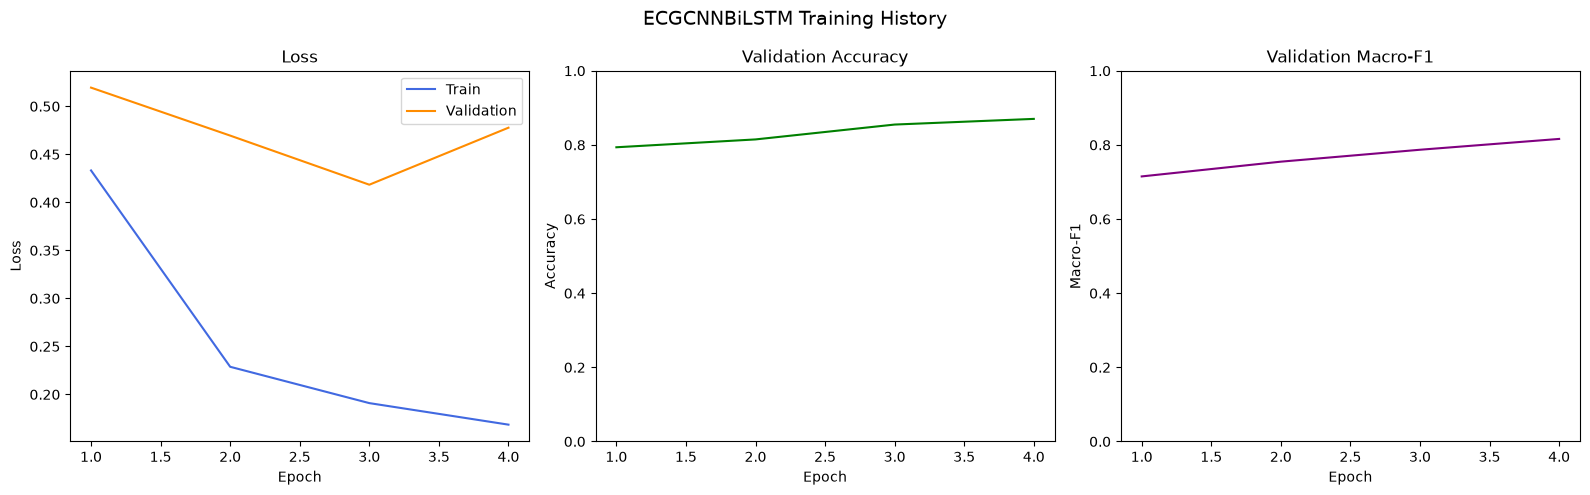

In [13]:
# ---- Plot training curves ----
history = getattr(globals().get('trainer'), '_history', {})
if not history:
    checkpoint = torch.load(config.BEST_MODEL_PATH, map_location='cpu', weights_only=False)
    history = checkpoint.get('history', {})

history_keys = ('train_loss', 'val_loss', 'val_accuracy', 'val_macro_f1')
if not history or not history.get('train_loss'):
    print('No epoch history is stored in this checkpoint. Run the training cell to generate training curves.')
else:
    history_length = len(history['train_loss'])
    missing_keys = [key for key in history_keys if key not in history or len(history[key]) != history_length]
    if missing_keys:
        raise ValueError(f'Checkpoint training history is incomplete or inconsistent: {missing_keys}')

    epochs = range(1, history_length + 1)
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    axes[0].plot(epochs, history['train_loss'], label='Train', color='royalblue')
    axes[0].plot(epochs, history['val_loss'], label='Validation', color='darkorange')
    axes[0].set_title('Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].legend()

    axes[1].plot(epochs, history['val_accuracy'], color='green')
    axes[1].set_title('Validation Accuracy')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].set_ylim(0, 1)

    axes[2].plot(epochs, history['val_macro_f1'], color='purple')
    axes[2].set_title('Validation Macro-F1')
    axes[2].set_xlabel('Epoch')
    axes[2].set_ylabel('Macro-F1')
    axes[2].set_ylim(0, 1)

    plt.suptitle('ECGCNNBiLSTM Training History', fontsize=14)
    plt.tight_layout()
    plt.show()

In [10]:
# ---- Confusion matrix on test set ----
cm = test_metrics['confusion_matrix']
class_labels = list(config.CLASS_NAMES.values())

# Normalise per row (recall per class)
cm_norm = cm.astype(float) / (cm.sum(axis=1, keepdims=True) + 1e-9)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, data, title, fmt in [
    (axes[0], cm,      'Confusion Matrix (counts)',    'd'),
    (axes[1], cm_norm, 'Confusion Matrix (normalised)', '.2f'),
]:
    sns.heatmap(
        data, annot=True, fmt=fmt, cmap='Blues',
        xticklabels=class_labels, yticklabels=class_labels, ax=ax
    )
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=30)
    ax.tick_params(axis='y', rotation=0)

plt.suptitle(f'Test Set | Accuracy={test_metrics["accuracy"]:.3f} | Macro-F1={test_metrics["macro_f1"]:.3f}', fontsize=13)
plt.tight_layout()
plt.show()

NameError: name 'test_metrics' is not defined

In [11]:
# ---- Per-class precision / recall / F1 from the evaluated test confusion matrix ----
from sklearn.metrics import classification_report

cm = np.asarray(test_metrics['confusion_matrix'], dtype=np.int64)
all_labels, all_preds = [], []
for true_class, row in enumerate(cm):
    for predicted_class, count in enumerate(row):
        all_labels.extend([true_class] * int(count))
        all_preds.extend([predicted_class] * int(count))

# Reuse evaluated predictions instead of decompressing and running the test set again.
print(classification_report(
    all_labels, all_preds,
    labels=list(config.CLASS_NAMES.keys()),
    target_names=list(config.CLASS_NAMES.values()),
    digits=4,
    zero_division=0,
))


NameError: name 'test_metrics' is not defined